<a href="https://colab.research.google.com/github/DalpesCS50/trab_estagio4_health-insurance-claims-prediction/blob/main/notebooks/KNN_%E2%80%94_HEALTH_INSURANCE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Nearest Neighbors (KNN) — HEALTH INSURANCE

Nesta etapa, será utilizado o K-Nearest Neighbors Regressor para prever
o valor de claim a partir das 12 preditoras da base HEALTH INSURANCE.

A implementação seguirá a sequência do notebook do professor, com
adaptações para as ausências, variáveis categóricas e registros repetidos
da nossa base. A preparação será ajustada somente no treinamento e
novamente dentro de cada fold de validação.

Será mantida a divisão por grupos utilizada na regressão linear:
10.527 observações de treinamento e 4.473 de teste, desde que seja
utilizada a mesma versão da base.

## Resultados da regressão linear para comparação

| Avaliação | R² | RMSE | MAE |
|---|---:|---:|---:|
| Teste externo | 0,754392 | 6.018,86 | 3.967,54 |
| Média da validação cruzada | 0,763194 | 5.898,75 | 3.847,89 |

O número de vizinhos será escolhido pela validação cruzada no treinamento,
utilizando o menor RMSE médio entre os valores avaliados. O teste externo
será utilizado para a avaliação final do modelo escolhido.

O PCA não será utilizado neste notebook; sua aplicação será examinada
na etapa de KNN com PCA.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    GridSearchCV,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


def rmse_score(real, previsto):
    return float(np.sqrt(mean_squared_error(real, previsto)))

In [2]:
def carrega_dados():
    url = (
        'https://raw.githubusercontent.com/DalpesCS50/'
        'trab_estagio4_health-insurance-claims-prediction/'
        'refs/heads/main/data/healthinsurance.csv'
    )
    df_raw = pd.read_csv(url)

    esperado = [
        'age', 'sex', 'weight', 'bmi', 'hereditary_diseases',
        'no_of_dependents', 'smoker', 'city', 'bloodpressure',
        'diabetes', 'regular_ex', 'job_title', 'claim'
    ]

    assert set(df_raw.columns) == set(esperado), 'Conferir as colunas da base.'
    df_raw = df_raw[esperado].copy()

    assert df_raw['claim'].notna().all(), 'A resposta contém ausências.'
    assert df_raw.index.is_unique

    # Identificar cópias exatas antes de qualquer tratamento.
    chaves = pd.MultiIndex.from_frame(df_raw)
    grupos = pd.Series(
        pd.factorize(chaves, sort=False)[0],
        index=df_raw.index,
        name='grupo'
    )

    X = df_raw.drop(columns='claim').copy()

    # Manter a regra adotada no relatório e na regressão.
    X['bloodpressure'] = X['bloodpressure'].mask(
        X['bloodpressure'].eq(0)
    )

    y = df_raw['claim'].copy()

    return df_raw, X, y, grupos


df_raw, X, y, grupos = carrega_dados()

display(X.head())
display(y.head().to_frame())

print('Dimensão de X:', X.shape, '| dimensão de y:', y.shape)
print('Linhas repetidas além da primeira:', df_raw.duplicated().sum())
print('Grupos de linhas distintas:', grupos.nunique())
print('Zeros originais em bloodpressure:', df_raw['bloodpressure'].eq(0).sum())

display(X.isna().sum())

,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title
0,60.0,male,64,24.3,NoDisease,1,0,NewYork,72.0,0,0,Actor
1,49.0,female,75,22.6,NoDisease,1,0,Boston,78.0,1,1,Engineer
2,32.0,female,64,17.8,Epilepsy,2,1,Phildelphia,88.0,1,1,Academician
3,61.0,female,53,36.4,NoDisease,1,1,Pittsburg,72.0,1,0,Chef
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82.0,1,0,HomeMakers


,claim
0,13112.6
1,9567.0
2,32734.2
3,48517.6
4,1731.7


Dimensão de X: (15000, 12) | dimensão de y: (15000,)
Linhas repetidas além da primeira: 1096
Grupos de linhas distintas: 13904
Zeros originais em bloodpressure: 756


,0
age,396
sex,0
weight,0
bmi,956
hereditary_diseases,0
no_of_dependents,0
smoker,0
city,0
bloodpressure,756
diabetes,0


In [3]:
separacao = GroupShuffleSplit(
    n_splits=1,
    train_size=0.7,
    random_state=1
)

idx_train, idx_test = next(
    separacao.split(X, y, groups=grupos)
)

X_train = X.iloc[idx_train].copy()
X_test = X.iloc[idx_test].copy()
y_train = y.iloc[idx_train].copy()
y_test = y.iloc[idx_test].copy()

grupos_train = grupos.iloc[idx_train].copy()
grupos_test = grupos.iloc[idx_test].copy()

# Conferir alinhamento e ausência de grupos compartilhados.
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert set(grupos_train).isdisjoint(set(grupos_test))
assert len(X_train) + len(X_test) == len(X)

# Conferir os tamanhos obtidos anteriormente na regressão.
assert X_train.shape == (10527, 12), 'Divisão diferente da regressão.'
assert X_test.shape == (4473, 12), 'Divisão diferente da regressão.'

print(
    'Treinamento:', X_train.shape,
    f'({len(X_train) / len(X):.2%} das linhas)'
)
print(
    'Teste:', X_test.shape,
    f'({len(X_test) / len(X):.2%} das linhas)'
)
print('Grupos separados e índices de X e y alinhados.')

display(X_test.head())

Treinamento: (10527, 12) (70.18% das linhas)
Teste: (4473, 12) (29.82% das linhas)
Grupos separados e índices de X e y alinhados.


,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82.0,1,0,HomeMakers
5,42.0,female,89,37.9,NoDisease,0,0,AtlanticCity,78.0,0,0,Dancer
6,18.0,male,59,23.8,NoDisease,0,0,Portland,64.0,0,0,Singer
7,21.0,male,52,26.8,NoDisease,0,0,Cambridge,74.0,1,0,Actor
12,19.0,male,45,24.6,NoDisease,1,0,York,NaN,0,1,Student


In [4]:
def cria_modelo_knn(n_neighbors=5):
    idade_bmi = Pipeline([
        ('imputacao', SimpleImputer(strategy='median')),
        ('escala', MinMaxScaler())
    ])

    peso_pressao = Pipeline([
        ('imputacao', SimpleImputer(strategy='median')),
        ('escala', StandardScaler())
    ])

    categoricas = Pipeline([
        ('imputacao', SimpleImputer(strategy='most_frequent')),
        ('codificacao', OneHotEncoder(
            drop='first',
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    preparacao = ColumnTransformer([
        ('idade_bmi', idade_bmi, ['age', 'bmi']),
        ('peso_pressao', peso_pressao, ['weight', 'bloodpressure']),
        ('numericas', 'passthrough', [
            'no_of_dependents', 'smoker', 'diabetes', 'regular_ex'
        ]),
        ('categoricas', categoricas, [
            'sex', 'hereditary_diseases', 'city', 'job_title'
        ])
    ], remainder='drop', verbose_feature_names_out=False)

    return Pipeline([
        ('preprocessamento', preparacao),
        ('knn', KNeighborsRegressor(n_neighbors=n_neighbors))
    ])

In [5]:
# Mesma organização de folds utilizada na regressão.
cv = GroupKFold(n_splits=10)

assert grupos_train.nunique() >= 10

knn_5 = cria_modelo_knn(n_neighbors=5)

cv_knn_5 = cross_validate(
    estimator=knn_5,
    X=X_train,
    y=y_train,
    groups=grupos_train,
    cv=cv,
    scoring=(
        'r2',
        'neg_root_mean_squared_error',
        'neg_mean_absolute_error'
    ),
    n_jobs=-1,
    error_score='raise'
)

resultados_knn_5 = pd.DataFrame({
    'fold': np.arange(1, 11),
    'R2': cv_knn_5['test_r2'],
    'RMSE': -cv_knn_5['test_neg_root_mean_squared_error'],
    'MAE': -cv_knn_5['test_neg_mean_absolute_error']
})

print('KNN com k = 5 — validação cruzada por grupos')
display(resultados_knn_5)

print('Resumo das métricas nos dez folds:')
display(
    resultados_knn_5[['R2', 'RMSE', 'MAE']].agg(['mean', 'std'])
)

KNN com k = 5 — validação cruzada por grupos


,fold,R2,RMSE,MAE
0,1,0.931353,3154.223218,1177.703229
1,2,0.932750,3107.661955,1085.354701
2,3,0.946647,2773.055319,1002.638272
3,4,0.929698,3092.507868,1086.034834
4,5,0.936658,3164.652010,1175.479335
5,6,0.923736,3273.494030,1287.568129
6,7,0.926993,3326.474669,1082.599373
7,8,0.932249,3216.861092,1143.161293
8,9,0.949734,2808.127133,997.575703
9,10,0.943268,2884.225670,1058.923726


Resumo das métricas nos dez folds:


,R2,RMSE,MAE
mean,0.935309,3080.128296,1109.70386
std,0.008615,193.498394,88.32237


In [6]:
knn_10 = cria_modelo_knn(n_neighbors=10)

cv_knn_10 = cross_validate(
    estimator=knn_10,
    X=X_train,
    y=y_train,
    groups=grupos_train,
    cv=cv,
    scoring=(
        'r2',
        'neg_root_mean_squared_error',
        'neg_mean_absolute_error'
    ),
    n_jobs=-1,
    error_score='raise'
)

resultados_knn_10 = pd.DataFrame({
    'fold': np.arange(1, 11),
    'R2': cv_knn_10['test_r2'],
    'RMSE': -cv_knn_10['test_neg_root_mean_squared_error'],
    'MAE': -cv_knn_10['test_neg_mean_absolute_error']
})

print('KNN com k = 10 — validação cruzada por grupos')
display(resultados_knn_10)

print('Resumo das métricas nos dez folds:')
display(
    resultados_knn_10[['R2', 'RMSE', 'MAE']].agg(['mean', 'std'])
)

KNN com k = 10 — validação cruzada por grupos


,fold,R2,RMSE,MAE
0,1,0.870164,4337.897110,2174.139516
1,2,0.885854,4048.717968,2001.411026
2,3,0.885807,4056.956954,2103.378215
3,4,0.881722,4011.249974,2080.005090
4,5,0.883690,4288.327609,2247.946410
5,6,0.853500,4537.010503,2357.672213
6,7,0.879243,4278.181682,2173.075878
7,8,0.884448,4201.094399,2159.433688
8,9,0.889480,4163.892208,2114.548774
9,10,0.892875,3963.333574,2128.306673


Resumo das métricas nos dez folds:


,R2,RMSE,MAE
mean,0.880678,4188.666198,2153.991748
std,0.011328,176.858823,96.979416


In [7]:
# Valores do professor, incluindo k = 10 já avaliado.
parametros = {
    'knn__n_neighbors': [3, 5, 7, 9, 10, 15, 25, 50, 75, 100, 200, 300]
}

# Conferir separação dos grupos e tamanho dos treinos internos.
for idx_treino, idx_val in cv.split(
    X_train, y_train, groups=grupos_train
):
    assert set(grupos_train.iloc[idx_treino]).isdisjoint(
        set(grupos_train.iloc[idx_val])
    )
    assert len(idx_treino) >= max(parametros['knn__n_neighbors'])

grid_cv = GridSearchCV(
    estimator=cria_modelo_knn(),
    param_grid=parametros,
    cv=cv,
    scoring={
        'RMSE': 'neg_root_mean_squared_error',
        'MAE': 'neg_mean_absolute_error',
        'R2': 'r2'
    },
    refit='RMSE',
    n_jobs=-1,
    return_train_score=True,
    error_score='raise'
)

# Apenas o treinamento participa da busca.
grid_cv.fit(
    X_train,
    y_train,
    groups=grupos_train
)

resultados_busca = pd.DataFrame({
    'k': [
        p['knn__n_neighbors']
        for p in grid_cv.cv_results_['params']
    ],
    'RMSE_treino': -grid_cv.cv_results_['mean_train_RMSE'],
    'RMSE_validacao': -grid_cv.cv_results_['mean_test_RMSE'],
    'desvio_RMSE_validacao': grid_cv.cv_results_['std_test_RMSE'],
    'MAE_validacao': -grid_cv.cv_results_['mean_test_MAE'],
    'R2_validacao': grid_cv.cv_results_['mean_test_R2'],
    'posicao_RMSE': grid_cv.cv_results_['rank_test_RMSE']
}).sort_values('k').reset_index(drop=True)

print('Resultados da busca por validação cruzada:')
display(resultados_busca)

print('Melhor k:', grid_cv.best_params_['knn__n_neighbors'])
print('Menor RMSE médio de validação:', -grid_cv.best_score_)
print('Modelo escolhido reajustado em todo o treinamento.')
print('O conjunto de teste ainda não foi avaliado.')

Resultados da busca por validação cruzada:


,k,RMSE_treino,RMSE_validacao,desvio_RMSE_validacao,MAE_validacao,R2_validacao,posicao_RMSE
0,3,2263.245536,3111.763591,150.656502,994.515391,0.934063,2
1,5,2410.538885,3080.128296,183.568695,1109.703860,0.935309,1
2,7,2752.639996,3441.740461,150.389151,1449.254517,0.919365,3
3,9,3232.523959,3942.246419,160.779184,1916.936867,0.894268,4
4,10,3498.639777,4188.666198,167.783012,2153.991748,0.880678,5
5,15,4702.207957,5292.727431,232.451034,3190.223871,0.809374,6
6,25,6219.763428,6598.441731,180.804757,4283.996318,0.704237,7
7,50,7385.933407,7580.024601,157.930963,5110.671310,0.609965,8
8,75,7789.982940,7913.062272,181.799776,5312.943137,0.575107,9
9,100,8046.956807,8151.338116,181.325556,5470.301689,0.549168,10


Melhor k: 5
Menor RMSE médio de validação: 3080.1282963523277
Modelo escolhido reajustado em todo o treinamento.
O conjunto de teste ainda não foi avaliado.


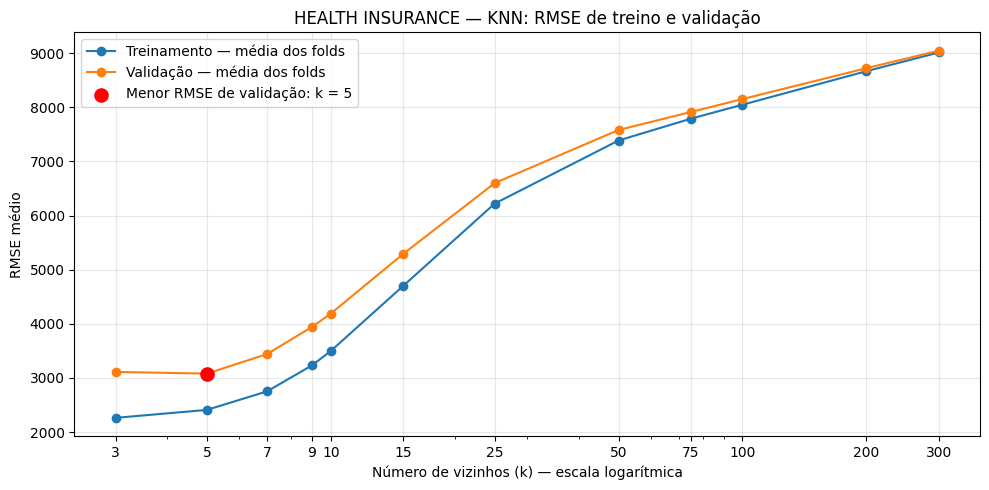

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    resultados_busca['k'],
    resultados_busca['RMSE_treino'],
    marker='o',
    label='Treinamento — média dos folds'
)

ax.plot(
    resultados_busca['k'],
    resultados_busca['RMSE_validacao'],
    marker='o',
    label='Validação — média dos folds'
)

melhor_k = grid_cv.best_params_['knn__n_neighbors']
melhor_rmse = -grid_cv.best_score_

ax.scatter(
    melhor_k,
    melhor_rmse,
    color='red',
    s=90,
    zorder=5,
    label=f'Menor RMSE de validação: k = {melhor_k}'
)

# Facilitar a visualização dos valores pequenos e grandes de k.
ax.set_xscale('log')
ax.set_xticks(resultados_busca['k'])
ax.set_xticklabels(resultados_busca['k'].astype(str))

ax.set_xlabel('Número de vizinhos (k) — escala logarítmica')
ax.set_ylabel('RMSE médio')
ax.set_title('HEALTH INSURANCE — KNN: RMSE de treino e validação')
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

In [9]:
valores_k = [
    p['knn__n_neighbors']
    for p in grid_cv.cv_results_['params']
]

grid_knn_df = pd.DataFrame(
    [
        -grid_cv.cv_results_[f'split{i}_test_RMSE']
        for i in range(grid_cv.n_splits_)
    ],
    columns=valores_k,
    index=pd.Index(
        range(1, grid_cv.n_splits_ + 1),
        name='fold'
    )
)

grid_knn_df.columns.name = 'k'

print('RMSE de validação por fold e número de vizinhos:')
display(grid_knn_df)

# Conferir se as médias reproduzem os resultados da busca.
assert np.allclose(
    grid_knn_df.mean().to_numpy(),
    -grid_cv.cv_results_['mean_test_RMSE']
)

print('Médias conferidas com os resultados do GridSearchCV.')

RMSE de validação por fold e número de vizinhos:


k,3,5,7,9,10,15,25,50,75,100,200,300
fold,,,,,,,,,,,,
1,3309.194824,3154.223218,3455.154491,4059.447454,4337.897110,5562.941744,6757.639847,7553.306162,7798.688640,8105.476354,8626.758406,9038.637532
2,3222.711744,3107.661955,3487.184084,3859.363915,4048.717968,5006.931424,6348.088606,7470.844169,7854.153962,8020.886903,8532.739828,8845.784511
3,2918.538241,2773.055319,3224.365439,3789.851549,4056.956954,5112.989412,6664.967760,7745.945570,7987.343772,8196.423133,8774.352319,9089.158126
4,3100.472368,3092.507868,3411.377679,3811.587707,4011.249974,5018.501251,6216.016259,7186.021729,7473.881834,7737.244873,8339.616099,8612.183727
5,3112.026604,3164.652010,3596.314187,4026.795489,4288.327609,5303.352928,6556.581958,7679.462918,8206.510144,8492.987030,9114.469467,9466.291565
6,3172.513431,3273.494030,3719.988916,4289.266226,4537.010503,5767.166272,6754.570944,7616.802050,7949.621098,8163.395909,8627.989852,8937.189267
7,3206.738147,3326.474669,3509.652713,4023.860702,4278.181682,5483.083263,6801.092621,7631.362350,7949.590970,8206.543032,8905.062027,9175.151020
8,3256.856120,3216.861092,3493.881433,3974.298804,4201.094399,5191.669596,6544.720735,7502.678966,7892.604461,8160.019542,8720.732063,9057.115051
9,3015.286946,2808.127133,3280.453207,3889.866302,4163.892208,5262.540370,6608.003940,7738.222430,8072.002559,8278.500365,8892.543867,9260.956274


Médias conferidas com os resultados do GridSearchCV.


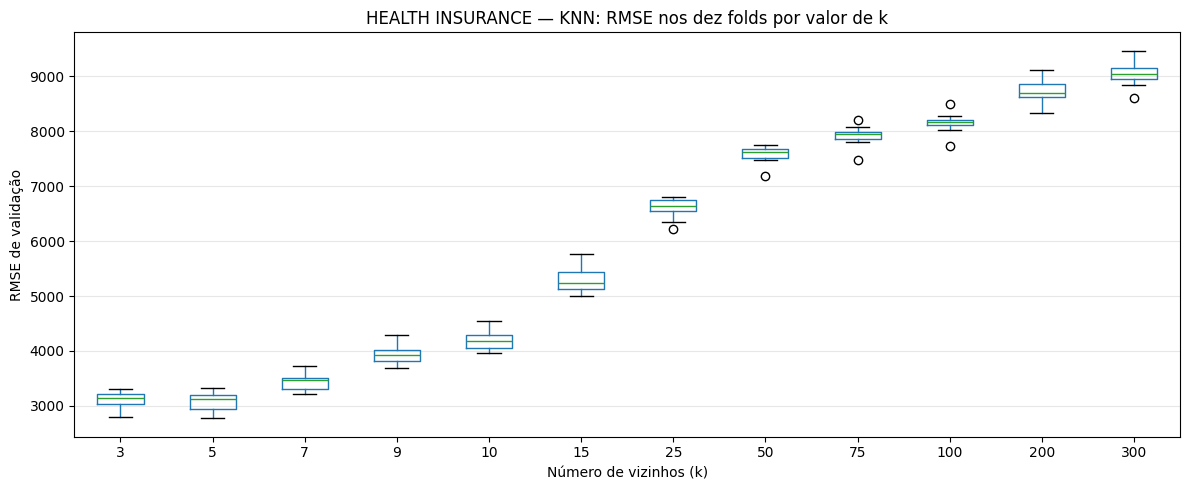

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))

grid_knn_df.boxplot(ax=ax, grid=False)

ax.set_xlabel('Número de vizinhos (k)')
ax.set_ylabel('RMSE de validação')
ax.set_title('HEALTH INSURANCE — KNN: RMSE nos dez folds por valor de k')
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

In [11]:
# Confirmar o valor escolhido exclusivamente pela validação.
melhor_k = grid_cv.best_params_['knn__n_neighbors']
assert melhor_k == 5, 'O melhor k difere do resultado conferido.'

# Previsões no conjunto de teste reservado.
knn_pred = grid_cv.predict(X_test)

metricas_knn_teste = {
    'RMSE': rmse_score(y_test, knn_pred),
    'MAE': mean_absolute_error(y_test, knn_pred),
    'R2': r2_score(y_test, knn_pred)
}

print(f'KNN com k = {melhor_k} — teste externo')
print(f"RMSE: {metricas_knn_teste['RMSE']:.6f}")
print(f"MAE:  {metricas_knn_teste['MAE']:.6f}")
print(f"R²:   {metricas_knn_teste['R2']:.6f}")

# Resultados de teste da regressão, registrados anteriormente.
comparacao_teste = pd.DataFrame([
    {
        'Modelo': 'Regressão linear',
        'RMSE': 6018.863496,
        'MAE': 3967.544566,
        'R2': 0.754392
    },
    {
        'Modelo': f'KNN — k = {melhor_k}',
        **metricas_knn_teste
    }
]).set_index('Modelo')

print('\nComparação no mesmo conjunto de teste:')
display(comparacao_teste)

# Comparar validação e teste do KNN escolhido.
i_melhor = grid_cv.best_index_

validacao_teste_knn = pd.DataFrame([
    {
        'Avaliação': 'Média da validação cruzada',
        'RMSE': -grid_cv.cv_results_['mean_test_RMSE'][i_melhor],
        'MAE': -grid_cv.cv_results_['mean_test_MAE'][i_melhor],
        'R2': grid_cv.cv_results_['mean_test_R2'][i_melhor]
    },
    {
        'Avaliação': 'Teste externo',
        **metricas_knn_teste
    }
]).set_index('Avaliação')

print('\nKNN escolhido — validação e teste:')
display(validacao_teste_knn)

KNN com k = 5 — teste externo
RMSE: 2933.325932
MAE:  1041.565844
R²:   0.941664

Comparação no mesmo conjunto de teste:


,RMSE,MAE,R2
Modelo,,,
Regressão linear,6018.863496,3967.544566,0.754392
KNN — k = 5,2933.325932,1041.565844,0.941664



KNN escolhido — validação e teste:


,RMSE,MAE,R2
Avaliação,,,
Média da validação cruzada,3080.128296,1109.703860,0.935309
Teste externo,2933.325932,1041.565844,0.941664
